# Project 9: Optimizer Comparison Using a Neural Network

**Objective:** Build a neural network using the Iris dataset and compare the training behavior and classification performance of SGD and Adam optimizers.

## Task 1: Load and Prepare the Iris Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.utils import to_categorical

iris = load_iris()
X = iris.data
y = iris.target

data = pd.DataFrame(X, columns=iris.feature_names)
data["species"] = [iris.target_names[i] for i in y]

display(data.head())
print("Dataset shape:", data.shape)
print("Classes:", iris.target_names)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)
Classes: ['setosa' 'versicolor' 'virginica']


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_encoded = to_categorical(y_train, num_classes=3)
y_test_encoded = to_categorical(y_test, num_classes=3)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## Task 2: Build and Train the Neural Network Using SGD and Adam

Both models use the same architecture, training data, number of epochs, and batch size. Only the optimizer changes, making the comparison fairer.

In [3]:
import tensorflow as tf

def build_model(optimizer):
    model = Sequential([
        Dense(8, activation="relu", input_shape=(4,)),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax")
    ])
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

np.random.seed(42)
tf.random.set_seed(42)

sgd_model = build_model(SGD(learning_rate=0.01))
sgd_history = sgd_model.fit(
    X_train, y_train_encoded,
    validation_split=0.2,
    epochs=100,
    batch_size=8,
    verbose=0
)

tf.random.set_seed(42)
adam_model = build_model(Adam(learning_rate=0.001))
adam_history = adam_model.fit(
    X_train, y_train_encoded,
    validation_split=0.2,
    epochs=100,
    batch_size=8,
    verbose=0
)

print("Both models trained successfully.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Both models trained successfully.


## Task 3: Compare Classification Performance

In [4]:
sgd_probabilities = sgd_model.predict(X_test, verbose=0)
adam_probabilities = adam_model.predict(X_test, verbose=0)

sgd_predictions = np.argmax(sgd_probabilities, axis=1)
adam_predictions = np.argmax(adam_probabilities, axis=1)

sgd_accuracy = accuracy_score(y_test, sgd_predictions)
adam_accuracy = accuracy_score(y_test, adam_predictions)

results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Test Accuracy": [sgd_accuracy, adam_accuracy],
    "Final Training Loss": [sgd_history.history["loss"][-1], adam_history.history["loss"][-1]],
    "Final Validation Accuracy": [sgd_history.history["val_accuracy"][-1], adam_history.history["val_accuracy"][-1]]
})

display(results)

,Optimizer,Test Accuracy,Final Training Loss,Final Validation Accuracy
0,SGD,0.766667,0.304991,0.791667
1,Adam,0.933333,0.143611,1.000000


In [5]:
print("SGD Classification Report")
print(classification_report(y_test, sgd_predictions, target_names=iris.target_names, zero_division=0))

print("Adam Classification Report")
print(classification_report(y_test, adam_predictions, target_names=iris.target_names, zero_division=0))

SGD Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.30      0.46        10
   virginica       0.59      1.00      0.74        10

    accuracy                           0.77        30
   macro avg       0.86      0.77      0.73        30
weighted avg       0.86      0.77      0.73        30

Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



## Compare Training Loss

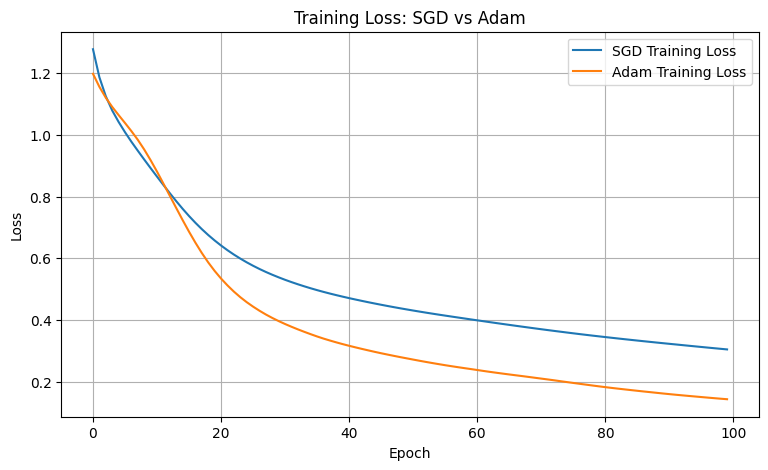

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["loss"], label="SGD Training Loss")
plt.plot(adam_history.history["loss"], label="Adam Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

## Compare Training Accuracy

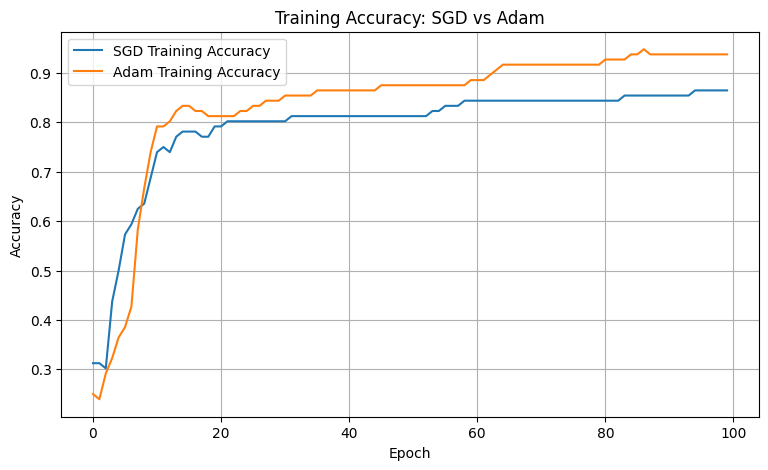

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_history.history["accuracy"], label="SGD Training Accuracy")
plt.plot(adam_history.history["accuracy"], label="Adam Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

## Compare Test Accuracy

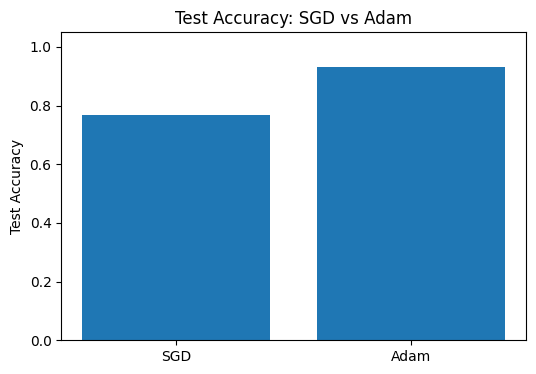

In [8]:
plt.figure(figsize=(6, 4))
plt.bar(results["Optimizer"], results["Test Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy: SGD vs Adam")
plt.show()

## Confusion Matrices

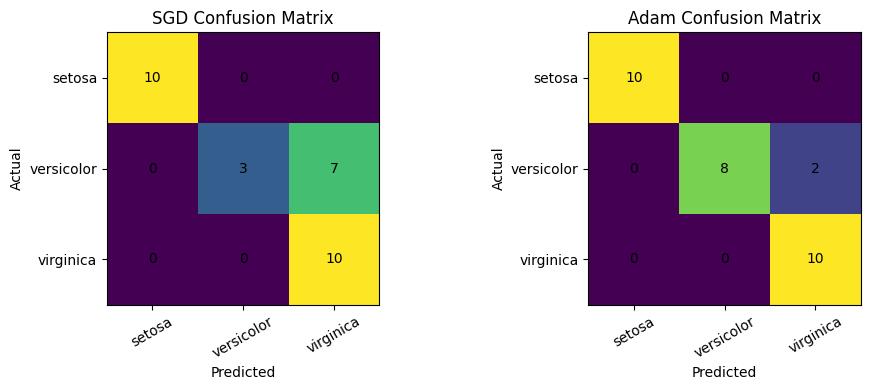

In [9]:
sgd_cm = confusion_matrix(y_test, sgd_predictions)
adam_cm = confusion_matrix(y_test, adam_predictions)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(sgd_cm)
axes[0].set_title("SGD Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticks(range(3), iris.target_names, rotation=30)
axes[0].set_yticks(range(3), iris.target_names)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, sgd_cm[i, j], ha="center", va="center")

axes[1].imshow(adam_cm)
axes[1].set_title("Adam Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_xticks(range(3), iris.target_names, rotation=30)
axes[1].set_yticks(range(3), iris.target_names)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, adam_cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Observation

SGD updates model parameters using the gradient and a fixed learning rate. Adam adapts parameter updates using information from previous gradients. Compare the loss curves, accuracy curves, test accuracy, and confusion matrices to see how the optimizers behaved on this run. The better optimizer should be identified from the measured results rather than assumed in advance.

## Result

A neural network was trained on the Iris dataset using SGD and Adam. Their training loss, training accuracy, test accuracy, and classification performance were compared using graphs and evaluation metrics.

## Conclusion

This experiment demonstrated how optimizer choice can affect neural network training. SGD uses a straightforward gradient update, while Adam adapts updates based on previous gradient information. The results show which optimizer performed better for this dataset and training setup.